# Air Quality Analysis of Indian Cities (2015-2020)
**Tools:** Python, Pandas, Matplotlib, Seaborn
**Dataset:** Air Quality Data in India (city_day.csv), 26 cities
**Goal:** Find which cities, seasons and pollutants have the worst air quality, and how it changed over time.

## 1. Load the Data
Import the libraries and load the dataset.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

files = glob.glob("/kaggle/**/city_day.csv", recursive=True)
print("Found:", files)

df = pd.read_csv(files[0])
df.head()

Found: ['/kaggle/input/datasets/shriyahjdggd/city-day-csv/city_day.csv']


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


## 2. Understand the Data
Check the size, missing values and data types. The dataset has 29,531 rows and 16 columns, with many missing pollutant readings.

In [15]:
df.shape


(29531, 16)

In [16]:
df.isnull().sum()


City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [17]:
df['Date'] = pd.to_datetime(df['Date'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   City        29531 non-null  object        
 1   Date        29531 non-null  datetime64[ns]
 2   PM2.5       24933 non-null  float64       
 3   PM10        18391 non-null  float64       
 4   NO          25949 non-null  float64       
 5   NO2         25946 non-null  float64       
 6   NOx         25346 non-null  float64       
 7   NH3         19203 non-null  float64       
 8   CO          27472 non-null  float64       
 9   SO2         25677 non-null  float64       
 10  O3          25509 non-null  float64       
 11  Benzene     23908 non-null  float64       
 12  Toluene     21490 non-null  float64       
 13  Xylene      11422 non-null  float64       
 14  AQI         24850 non-null  float64       
 15  AQI_Bucket  24850 non-null  object        
dtypes: datetime64[ns](1), 

## 3. Data Cleaning
- Check for duplicates
- Remove rows with no AQI
- Fill missing pollutant values with the city median, then the overall median

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df = df.drop_duplicates()

In [20]:
df = df.dropna(subset=['AQI'])
df.shape

(24850, 16)

In [21]:
pollutants = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene','Xylene']

for col in pollutants:
    df[col] = df.groupby('City')[col].transform(lambda x: x.fillna(x.median()))

In [22]:
df.isnull().sum()

City              0
Date              0
PM2.5             0
PM10           1893
NO                0
NO2               0
NOx             771
NH3            1334
CO                0
SO2               0
O3              153
Benzene        2259
Toluene        4084
Xylene        12381
AQI               0
AQI_Bucket        0
dtype: int64

In [23]:
for col in pollutants:
    df[col] = df[col].fillna(df[col].median())

df.isnull().sum()

City          0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
Xylene        0
AQI           0
AQI_Bucket    0
dtype: int64

## 4. Create New Columns
Add Year, Month and Season columns to study trends over time.

In [24]:
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

df['Season'] = df['Month'].map({12:'Winter',1:'Winter',2:'Winter',
                                3:'Summer',4:'Summer',5:'Summer',
                                6:'Monsoon',7:'Monsoon',8:'Monsoon',9:'Monsoon',
                                10:'Post-Monsoon',11:'Post-Monsoon'})
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket,Year,Month,Season
28,Ahmedabad,2015-01-29,83.13,107.67,6.93,28.71,33.72,17.055,6.93,49.52,59.76,0.02,0.00,3.14,209.0,Poor,2015,1,Winter
29,Ahmedabad,2015-01-30,79.84,107.67,13.85,28.68,41.08,17.055,13.85,48.49,97.07,0.04,0.00,4.81,328.0,Very Poor,2015,1,Winter
30,Ahmedabad,2015-01-31,94.52,107.67,24.39,32.66,52.61,17.055,24.39,67.39,111.33,0.24,0.01,7.67,514.0,Severe,2015,1,Winter
31,Ahmedabad,2015-02-01,135.99,107.67,43.48,42.08,84.57,17.055,43.48,75.23,102.70,0.40,0.04,25.87,782.0,Severe,2015,2,Winter
32,Ahmedabad,2015-02-02,178.33,107.67,54.56,35.31,72.80,17.055,54.56,55.04,107.38,0.46,0.06,35.61,914.0,Severe,2015,2,Winter


## 5. Exploratory Data Analysis
### Chart settings

In [25]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

### AQI Distribution
Most days have low to medium AQI, with a long tail of very high days.

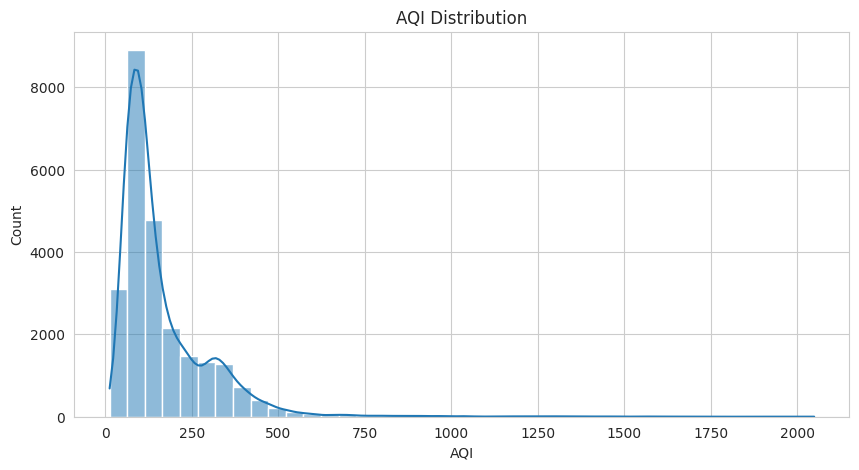

In [26]:
sns.histplot(df['AQI'], bins=40, kde=True)
plt.title("AQI Distribution")
plt.show()

### Number of Days by AQI Category
Most days are Moderate or Satisfactory, but many days are Very Poor or Severe.

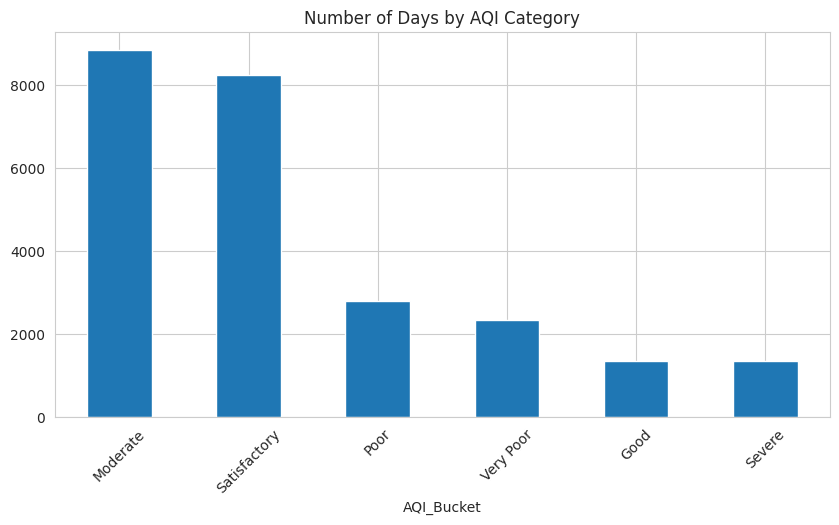

In [27]:
df['AQI_Bucket'].value_counts().plot(kind='bar')
plt.title("Number of Days by AQI Category")
plt.xticks(rotation=45)
plt.show()

### Most Polluted Cities
Ahmedabad has the highest average AQI, followed by Delhi, Patna, Gurugram and Lucknow.

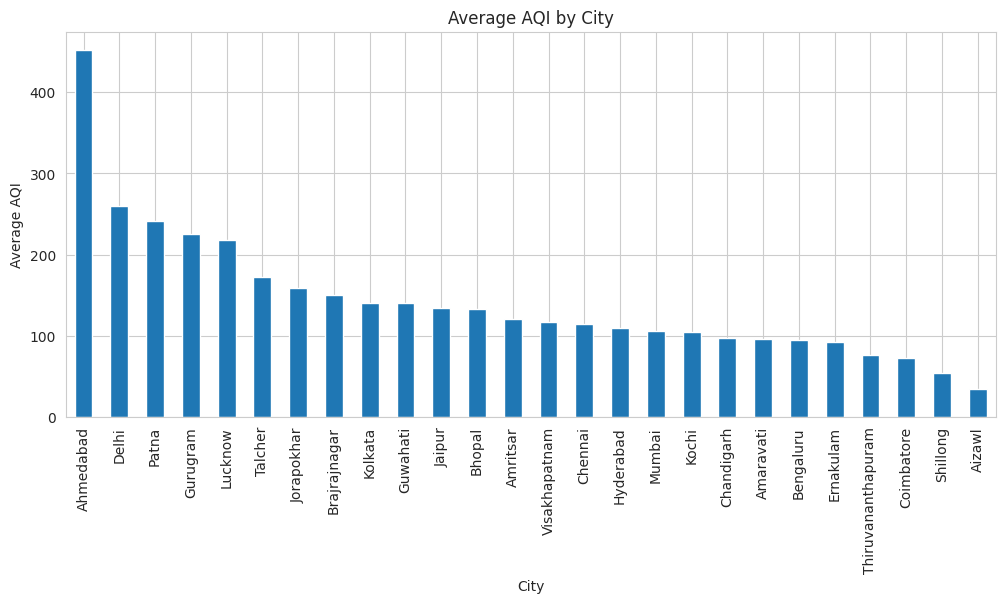

City
Ahmedabad    452.122939
Delhi        259.487744
Patna        240.782042
Gurugram     225.123882
Lucknow      217.973059
Name: AQI, dtype: float64

In [28]:
city_aqi = df.groupby('City')['AQI'].mean().sort_values(ascending=False)
city_aqi.plot(kind='bar', figsize=(12, 5))
plt.title("Average AQI by City")
plt.ylabel("Average AQI")
plt.show()

city_aqi.head()

### AQI Trend by Year
Average AQI fell from about 213 in 2015 to about 114 in 2020.

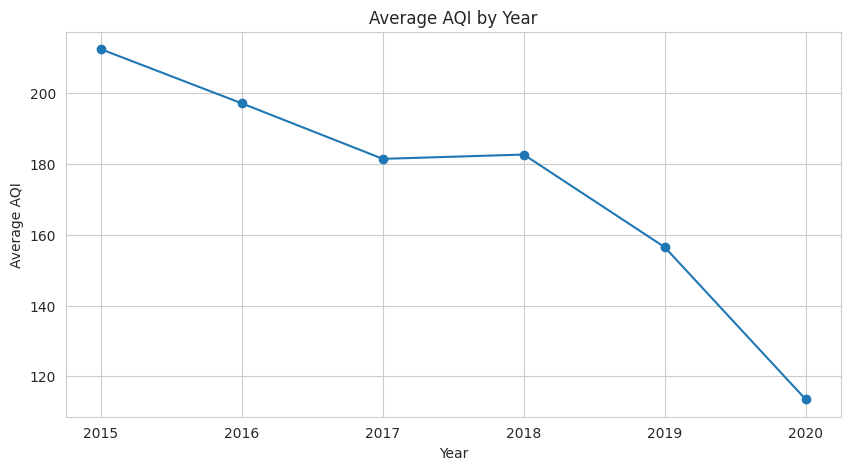

In [29]:
df.groupby('Year')['AQI'].mean().plot(marker='o')
plt.title("Average AQI by Year")
plt.ylabel("Average AQI")
plt.show()

### AQI by Season
Winter is the most polluted season and Monsoon is the cleanest.

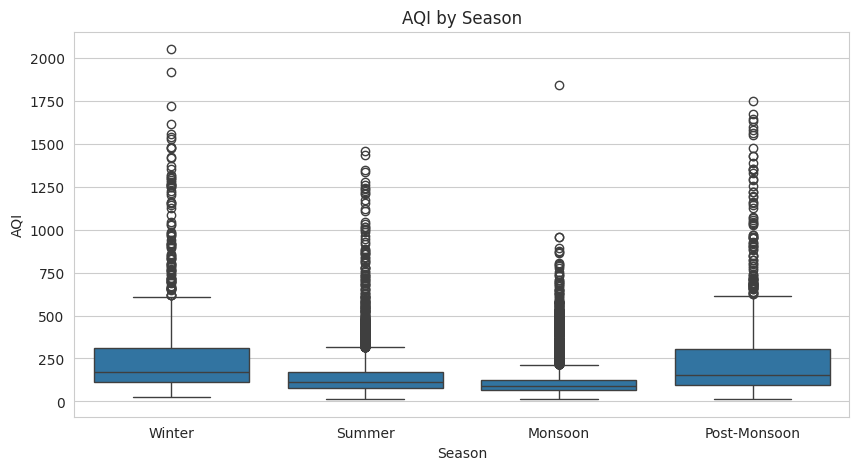

In [30]:
sns.boxplot(x='Season', y='AQI', data=df)
plt.title("AQI by Season")
plt.show()

### Compare Selected Cities Over Time
Delhi, Mumbai, Chennai and Kolkata compared across the years.

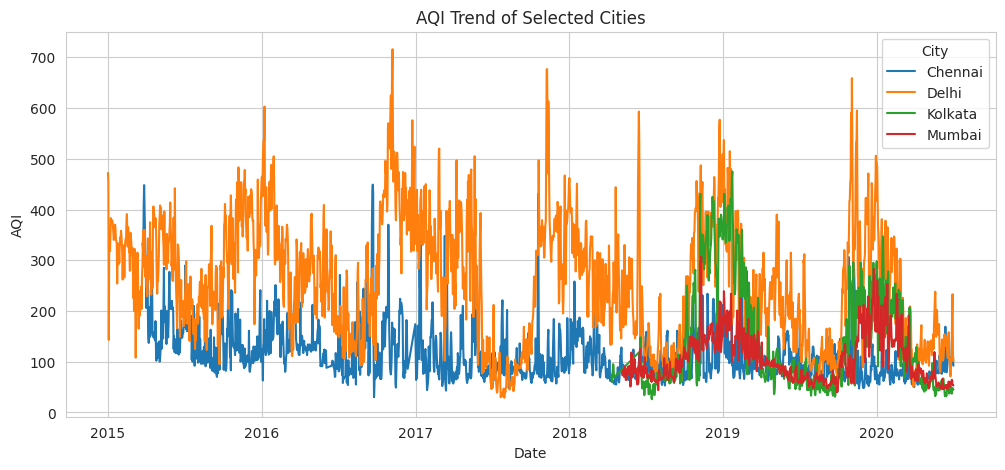

In [31]:
cities = ['Delhi', 'Mumbai', 'Chennai', 'Kolkata']
subset = df[df['City'].isin(cities)]

plt.figure(figsize=(12, 5))
sns.lineplot(x='Date', y='AQI', hue='City', data=subset)
plt.title("AQI Trend of Selected Cities")
plt.show()

### Correlation Between Pollutants and AQI
CO and PM2.5 have the strongest link with AQI.

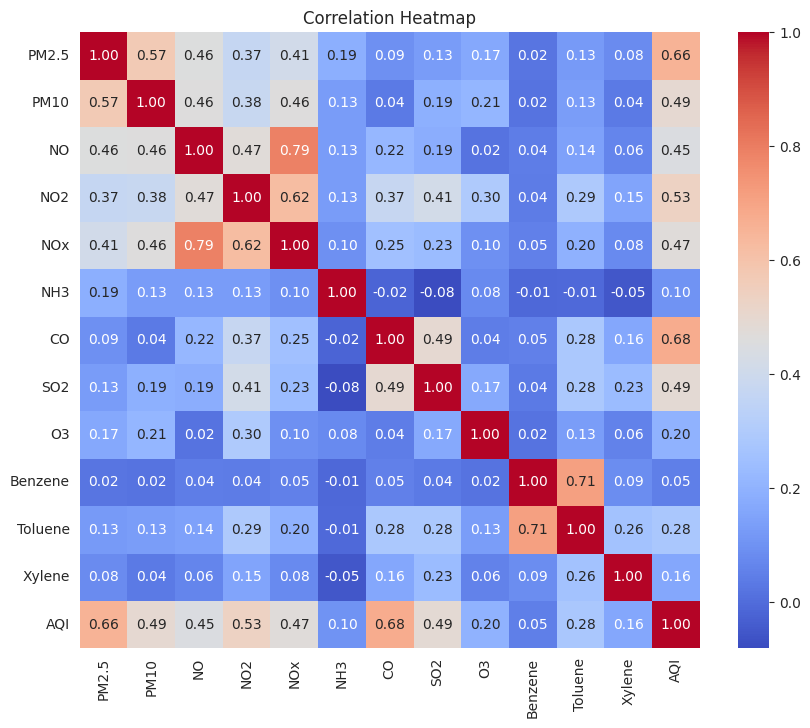

In [32]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[pollutants + ['AQI']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

### Effect of the COVID-19 Lockdown
Compare 25 March to 30 June 2020 with the same period in 2019.

In [33]:
lockdown = df[(df['Date'] >= '2020-03-25') & (df['Date'] <= '2020-06-30')]
last_year = df[(df['Date'] >= '2019-03-25') & (df['Date'] <= '2019-06-30')]

print("Lockdown 2020 average AQI:", round(lockdown['AQI'].mean(), 1))
print("Same period 2019 average AQI:", round(last_year['AQI'].mean(), 1))

Lockdown 2020 average AQI: 84.2
Same period 2019 average AQI: 143.9


## 6. Key Insights
1. Ahmedabad is the most polluted city (average AQI about 452), followed by Delhi (260), Patna (241), Gurugram (225) and Lucknow (218).
2. Aizawl (35), Shillong (54) and Coimbatore (73) have the cleanest air.
3. Winter is the most polluted season (average AQI about 221), followed closely by Post-Monsoon (216). Monsoon is the cleanest (116) because rain washes pollutants out of the air.
4. Air quality improved over time: average AQI fell from about 213 in 2015 to about 114 in 2020.
5. CO (0.68) and PM2.5 (0.66) have the strongest link with AQI, followed by NO2 (0.53).
6. During the COVID lockdown (25 March to 30 June 2020), average AQI was about 84, compared to about 144 in the same period of 2019. This is a drop of about 42%.
7. Most days fall in the Moderate or Satisfactory category, but over 2,300 days were Very Poor and over 1,300 days were Severe.

## 7. Conclusion
Air pollution in India varies a lot by city and season. Northern and western cities such as Ahmedabad, Delhi, Patna and Lucknow are the worst affected, and winter is the most dangerous time of year. Fine particles (PM2.5) and CO are the main drivers of high AQI. The sharp fall during the 2020 lockdown shows that reducing traffic and industrial activity can improve air quality quickly.

**Recommendations**
- Focus pollution control efforts on winter and post-monsoon months.
- Reduce vehicle and industrial emissions in the most polluted cities.
- Monitor PM2.5 and CO closely, since they affect AQI the most.

**Limitation:** Many pollutant values were missing and were filled with medians, so results are approximate.